In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
count=0

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        count+=1
        if count>20:
            break

    if count>20:
        break
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/tensorflow-great-barrier-reef/example_sample_submission.csv
/kaggle/input/competitions/tensorflow-great-barrier-reef/example_test.npy
/kaggle/input/competitions/tensorflow-great-barrier-reef/train.csv
/kaggle/input/competitions/tensorflow-great-barrier-reef/test.csv
/kaggle/input/competitions/tensorflow-great-barrier-reef/greatbarrierreef/competition.cpython-37m-x86_64-linux-gnu.so
/kaggle/input/competitions/tensorflow-great-barrier-reef/greatbarrierreef/__init__.py
/kaggle/input/competitions/tensorflow-great-barrier-reef/train_images/video_1/6234.jpg
/kaggle/input/competitions/tensorflow-great-barrier-reef/train_images/video_1/1269.jpg
/kaggle/input/competitions/tensorflow-great-barrier-reef/train_images/video_1/3863.jpg
/kaggle/input/competitions/tensorflow-great-barrier-reef/train_images/video_1/6241.jpg
/kaggle/input/competitions/tensorflow-great-barrier-reef/train_images/video_1/10304.jpg
/kaggle/input/competitions/tensorflow-great-barrier-reef/train_ima

In [2]:
import pandas as pd
from glob import glob
import cv2
import numpy as np
import torch

base_dir='../input/competitions/tensorflow-great-barrier-reef/train_images/'

In [3]:
train_df=pd.read_csv('/kaggle/input/competitions/tensorflow-great-barrier-reef/train.csv')

#문자열을 리스트로 바꾸기(eval 함수)
train_df['annotations'] =train_df['annotations'].apply(eval)
train_df['image_path'] = train_df.apply(lambda x: f"video_{x['video_id']}/{x['video_frame']}.jpg", axis=1)

train_df.head(20)

,video_id,sequence,video_frame,sequence_frame,image_id,annotations,image_path
0,0,40258,0,0,0-0,[],video_0/0.jpg
1,0,40258,1,1,0-1,[],video_0/1.jpg
2,0,40258,2,2,0-2,[],video_0/2.jpg
3,0,40258,3,3,0-3,[],video_0/3.jpg
4,0,40258,4,4,0-4,[],video_0/4.jpg
5,0,40258,5,5,0-5,[],video_0/5.jpg
6,0,40258,6,6,0-6,[],video_0/6.jpg
7,0,40258,7,7,0-7,[],video_0/7.jpg
8,0,40258,8,8,0-8,[],video_0/8.jpg
9,0,40258,9,9,0-9,[],video_0/9.jpg


In [4]:
img = cv2.imread(f"{base_dir}video_0/0.jpg")
print(img.shape)

(720, 1280, 3)


In [5]:
#전체 프레임 수의 90% 지점을 기준으로 앞쪽은 Train, 뒤쪽은 Val로 쪼개기
#복잡한 서브시퀀스 계산 없이, 비디오 ID 내에서 단순 시간(프레임 순서)으로 가르기
#이러면 약간의 data leakage가 발생한다. 일단 베이스라인 코드는 이렇게 작성

train_df_list = []
val_df_list = []

for video_id in [0, 1, 2]:
    video_data = train_df[train_df['video_id'] == video_id].sort_values('video_frame')
    split_idx = int(len(video_data) * 0.9)
    
    train_df_list.append(video_data.iloc[:split_idx])
    val_df_list.append(video_data.iloc[split_idx:])

# 다시 하나로 합치기
train_df = pd.concat(train_df_list).reset_index(drop=True)
val_df = pd.concat(val_df_list).reset_index(drop=True)

train_df.shape[0], val_df.shape[0]

(21149, 2352)

In [6]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

train_transform=A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    ToTensorV2()
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))   #label_field에 등록해놓으면 bbox랑 같이 필터링해준다.pascal_voc는 절대좌표 입력

#faster rcnn은 resize도 모델 내부에서

test_transform=A.Compose([
    ToTensorV2()
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))

/usr/local/lib/python3.12/dist-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


In [7]:
from torch.utils.data import Dataset

class ReefDataset(Dataset):
    def __init__(self, df, transform=None):
        super().__init__()
        self.df=df
        self.transform=transform

    def get_boxes(self, row):

        if len(row['annotations']) == 0:
            # 박스가 아예 없는 경우 -> 빈 (0, 4) 배열로 명시적 처리
            return np.zeros((0, 4), dtype=np.float32)
            
        boxes = np.array([[a['x'], a['y'], a['width'], a['height']] for a in row['annotations']], dtype=np.float32)
         
        if boxes.ndim == 1:
            boxes = boxes.reshape(1, -1)
            
        #[x_min, y_min, w, h]을 [x_min, y_min, x_max, y_max]로 바꾸기
        boxes[:,2]=boxes[:,0]+boxes[:,2]
        boxes[:,3]=boxes[:,1]+boxes[:,3]
        return boxes

    #증강할때 bbox 크가가 이미지 크기 넘어가면 에러. 미리 확인해주기
    def can_augment(self, boxes):
        box_outside_image = ((boxes[:, 0] < 0).any() or (boxes[:, 1] < 0).any() 
                             or (boxes[:, 2] > 1280).any() or (boxes[:, 3] > 720).any())
        
        return not box_outside_image

    def get_image(self, row):
        img=cv2.imread(f'{base_dir}{row['image_path']}', cv2.IMREAD_COLOR)  #IMREAD_COLOR은 강제 3채널 변경
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)  #cv2.imread는 unit8로 반환. 정규화를 위해 float32로.
        img/=255.0  #torchvision의 rcnn은 내부에서 imagenet mean/std로 정규화. 따라서 미리 0~1사이 픽셀값 가지도록 하기.
        return img

    def __getitem__(self, idx):
        row=self.df.iloc[idx]
        image=self.get_image(row)
        boxes=self.get_boxes(row)

        n_boxes=boxes.shape[0]

        #target인자 중 area 계산하기. loss계산이나 순전파에는 사용 안되지만 coco eval이나 iscrowd영역 eval에서 제외할 때 사용
        area=(boxes[:,2]-boxes[:,0])*(boxes[:,3]-boxes[:,1])

        target={
            'image_id': torch.tensor([idx], dtype=torch.int64),  #스칼라 텐서가 아닌 1차원 텐서를 rcnn이 받음.그래서 []사용
            'boxes': torch.as_tensor(boxes, dtype=torch.float32),  #as_tensor로 복사 없이 기존 메모리를 그대로 참조
            'labels': torch.ones((n_boxes,), dtype=torch.int64),  #만드는 텐서의 모양을 튜플로 받음
            'area': torch.as_tensor(area, dtype=torch.float32),   #나중에 eval할때 크기별로 평가하기 위해 사용. 학습에 연관 없음.
            'is_crowd': torch.zeros((n_boxes,), dtype=torch.int64)  #is_crowd인 area없음. is_crowd영역은 eval에서 특별취급
        }
        

        if self.transform and self.can_augment(boxes):
            sample = {
                'image': image,
                'bboxes': target['boxes'].numpy(),
                'labels': target['labels'].numpy()
            }
            sample = self.transform(**sample)
            image = sample['image']

            if n_boxes>0:
                target['boxes'] = torch.tensor(sample['bboxes'], dtype=torch.float32)   #sample의 boxes는 튜플 개수만큼의 리스트.텐서로 바꿔주기

        else:
            image=ToTensorV2()(image=image)['image']

        return image, target


    def __len__(self):
        return len(self.df)

In [8]:
train_dataset=ReefDataset(train_df, train_transform)
val_dataset=ReefDataset(val_df, test_transform)

In [9]:
train_df[train_df['annotations'].str.len()>10].head()

,video_id,sequence,video_frame,sequence_frame,image_id,annotations,image_path
8621,1,8503,4140,312,1-4140,"[{'x': 1073, 'y': 274, 'width': 62, 'height': ...",video_1/4140.jpg
8622,1,8503,4141,313,1-4141,"[{'x': 1076, 'y': 270, 'width': 67, 'height': ...",video_1/4141.jpg
8623,1,8503,4142,314,1-4142,"[{'x': 1072, 'y': 268, 'width': 72, 'height': ...",video_1/4142.jpg
8624,1,8503,4143,315,1-4143,"[{'x': 1074, 'y': 264, 'width': 73, 'height': ...",video_1/4143.jpg
8625,1,8503,4144,316,1-4144,"[{'x': 1080, 'y': 260, 'width': 70, 'height': ...",video_1/4144.jpg


In [10]:
image, target=train_dataset[8621]
target

{'image_id': tensor([8621]),
 'boxes': tensor([[ 145.0000,  403.0000,  207.0000,  446.0000],
         [ 900.0000,  376.0000,  921.0000,  399.0000],
         [ 655.0000,  616.0000,  684.0000,  647.0000],
         [ 601.0000,  546.0000,  643.0000,  588.0000],
         [ 546.0000,  488.0000,  601.0000,  544.0000],
         [ 950.0000,  547.0000,  998.0000,  577.0000],
         [ 540.0000,  515.0000,  568.0000,  555.0000],
         [ 909.0000,  576.0000,  928.0000,  602.0000],
         [1067.0000,  468.0000, 1090.0000,  503.0000],
         [1041.0000,  439.0000, 1066.0000,  466.0000],
         [ 656.0000,  361.0000,  686.0000,  390.0000]]),
 'labels': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]),
 'area': tensor([2666.,  483.,  899., 1764., 3080., 1440., 1120.,  494.,  805.,  675.,
          870.]),
 'is_crowd': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])}

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..220.0].


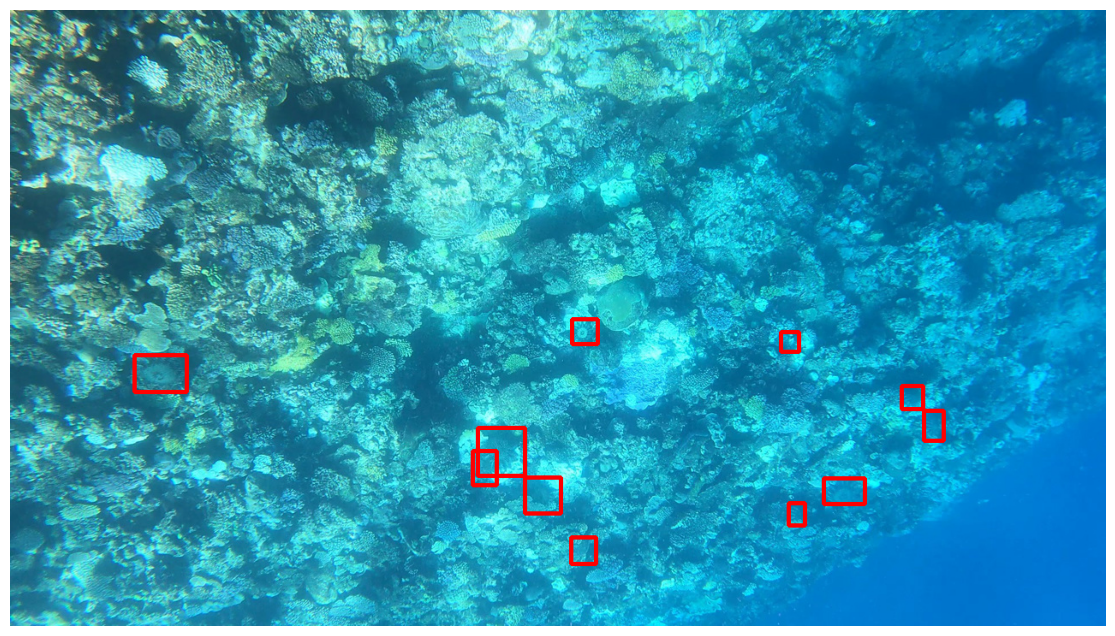

In [11]:
import matplotlib.pyplot as plt

boxes = target['boxes'].cpu().numpy().astype(np.int32)
img = image.permute(1,2,0).cpu().numpy()  #이미지가 텐서 타입이므로 순서 바꿔주기
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

for box in boxes:
    cv2.rectangle(img,
                  (box[0], box[1]),
                  (box[2], box[3]),
                  (220, 0, 0), 3)
    
ax.set_axis_off()
ax.imshow(img)

In [12]:
import random
import torch

def set_seed(seed=42):
    random.seed(seed)    #파이선 기본 내장 random 모듈 시드
    np.random.seed(seed)    #numpy 랜덤 시드, albumentation가 numpy랜덤 모듈을 사용
    torch.manual_seed(seed)    #CPU에서 동작하는 pytorch 랜덤 시드(모델 가중치 초기화 등)
    torch.cuda.manual_seed(seed)       # 단일 GPU용
    torch.cuda.manual_seed_all(seed)    #멀티 GPU에서 동작하는 pytorch 랜덤 시드(dropout 등)


#worker init fn(서브 프로세스 시드 고정)
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()  # 제너레이터 생성
g.manual_seed(0)  # 제너레이터 시드값 고정
#전역 시드 고정해도 프로세스들의 순서가 달라지면 학습되는 데이터 순서가 달라질 수 있으므로 shuffle을 통제

set_seed()

In [13]:
from torch.utils.data import DataLoader

def collator(batch):
    return tuple(zip(*batch))

train_dataloader=DataLoader(train_dataset, batch_size=4, shuffle=True, drop_last=True, 
                            num_workers=4, worker_init_fn=seed_worker, generator=g, collate_fn=collator)
val_dataloader=DataLoader(val_dataset, batch_size=4, shuffle=False, drop_last=False, 
                          num_workers=4, worker_init_fn=seed_worker, generator=g, collate_fn=collator)

In [14]:
from torchvision import models
from torchvision import ops
from torchvision.models.detection import rpn
from torchvision.models.detection import FasterRCNN

device='cuda' if torch.cuda.is_available() else 'cpu'

backbone=models.vgg16(weights='VGG16_Weights.IMAGENET1K_V1').features
backbone.out_channels=512 #faster rcnn 앵커에서 참조함

anchor_generator=rpn.AnchorGenerator(
    sizes=((32,64,128),),
    aspect_ratios=((0.5,1.0,2.0,))
)

model=FasterRCNN(
    backbone=backbone,
    num_classes=2,
    rpn_anchor_generator=anchor_generator,
    min_size=480,  
    max_size=800
).to(device)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 182MB/s]


In [15]:
from torch import optim
from torch import nn

grad_params=[p for p in model.named_parameters() if p[1].requires_grad]

no_decay = ["bias", "norm"]   # Bias나 LayerNorm은 weight decay 사용 안하고 보호(bias는 과적합에 영향x, layernorm은 모델 표현력을 올려주는 계층)

optimizer_grouped_parameters = [
    {
        "params": [p for n, p in grad_params if not any(nd in n for nd in no_decay)],
        "weight_decay": 1e-2,  #weight decay가 그래디언트 항하고 분리, lr과 곱해져서 빼지기 때문에 큰 값 아님.그리고 vit는 과적합에 취약
    },
    {
        "params": [p for n, p in grad_params if any(nd in n for nd in no_decay)],
        "weight_decay": 0.0, 
    },
]

optimizer = optim.AdamW(optimizer_grouped_parameters, lr=1e-3)

#스케쥴러 설정-0.5배씩 줄이기
scheduler=optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

In [16]:
from tqdm.notebook import tqdm

best_val_loss=float('inf')
save_path='best_cots_model.pt'
for epoch in range(5):
    
    #모델 훈련
    model.train()
    train_loss=0.0

    for images, targets in tqdm(train_dataloader):
        images=list(image.to(device) for image in images)
        targets=[{k:v.to(device) for k,v in t.items()} for t in targets]

        loss_dict=model(images, targets)
        losses=sum(loss for loss in loss_dict.values())
        
        optimizer.zero_grad()
        losses.backward()   #loss dict에 있는 값들이 다 낮아져야 하므로 loss를 다 더해서 역전파 진행
        optimizer.step()

        train_loss+=losses.item()


    train_loss=train_loss/len(train_dataloader)
    print(f'Epoch: {epoch+1:4d}, Train Loss: {train_loss:.4f}')

    model.train()  #faster rcnn은 eval 모드에서 loss를 반환하지 않음. 그래서 val에서도 train 모
    val_loss=0

    with torch.no_grad():
        for images, targets in tqdm(val_dataloader):
            images=list(image.to(device) for image in images)
            targets=[{k:v.to(device) for k,v in t.items()} for t in targets]

            loss_dict=model(images, targets)
            losses=sum(loss for loss in loss_dict.values())

            val_loss+=losses.item()*len(images)

    val_loss=val_loss/len(val_dataloader.dataset)

    scheduler.step(val_loss)
    current_lr=optimizer.param_groups[0]['lr']
    print(f'Validation Loss: {val_loss:.4f}, Current LR: {current_lr:.6f}')

    if val_loss<best_val_loss:
        print('가장 낮은 val loss 기록, 모델 저장')

        best_val_loss=val_loss
        torch.save(model.state_dict(), save_path)

  0%|          | 0/5287 [00:00<?, ?it/s]

Epoch:    1, Train Loss: 5.6931


  0%|          | 0/588 [00:00<?, ?it/s]

Validation Loss: 0.0078, Current LR: 0.001000
가장 낮은 val loss 기록, 모델 저장


  0%|          | 0/5287 [00:00<?, ?it/s]

...

Validation Loss: 0.0105, Current LR: 0.000500


  0%|          | 0/5287 [00:00<?, ?it/s]

Epoch:    5, Train Loss: 0.0299


  0%|          | 0/588 [00:00<?, ?it/s]

Validation Loss: 0.0088, Current LR: 0.000500
